# Sea ice volume budget for ACCESS-OM3
Compares the sea ice volume budget (growth and melt terms) of an OM3 run with ACCESS-OM2, as a monthly climatology and as annual timeseries.

Questions:
  1) How does OM3 compare with OM2?
  2) Does the sum of freeze + melt match the `dvidtt` diagnostic?

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/"
nbname = "SeaIce_mass_budget_climatology.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import calendar
import xarray as xr
import numpy as np
from datetime import timedelta
import intake
import dask
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean.cm as cmo
import xesmf
from scipy.ndimage import distance_transform_edt
from distributed import Client

from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3


In [5]:
IAF = esm_file.find('iaf') > 0

# ACCESS-CM3 is a coupled present-day control, so compare it against the interannually
# forced OM2 run rather than the RYF spin-up: the RYF record is 1900-2549, which next to
# a 50-year CM3 run squashes it into a spike on the annual plots below.
# NOTE: this is still an ACCESS-OM2 reference, not ACCESS-CM2. cj877 does not write the
# CICE budget terms this notebook needs (congel/frazil/snoice/melt*/dvidt*); it has the
# SIMIP sidmass* set instead, which would need a mass-to-volume conversion to compare.
use_iaf_reference = IAF or model_name == "ACCESS-CM3"
IAF, use_iaf_reference

(False, True)

In [6]:
if use_iaf_reference:
    om2_exp = '025deg_jra55_iaf_omip2_cycle6'
else:
    om2_exp = '025deg_jra55_ryf9091_gadi'

# Names used in panel titles, legends and captions. model_label follows the datastore,
# so an ACCESS-CM3 run is not labelled ACCESS-OM3. ref_label names whatever reference is
# actually loaded below -- currently always the ACCESS-OM2 run in om2_exp, including for
# CM3 runs, because cj877 (ACCESS-CM2) does not write the CICE budget terms this notebook
# needs (it has the SIMIP sidmass* set instead). Change it with the reference, not before.
model_label = model_name          # ACCESS-OM3 or ACCESS-CM3
ref_label = "ACCESS-OM2"

In [7]:
client = Client(threads_per_worker=1)
client.dashboard_link

'http://127.0.0.1:8787/status'

### Load ACCESS-OM3 sea ice mass budget diagnostics using the ESM datastore

In [8]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [9]:
# One chunk per variable per monthly file (the whole 1152x1440 field, ~13 MB). The files are
# stored in 384x720 blocks, which dask would otherwise copy, giving ~6x as many tiny tasks.
full_field = {"nj": -1, "ni": -1}

variables = ["aice_m", "congel_m", "frazil_m", "snoice_m", "meltt_m", "meltb_m", "meltl_m", "evap_ai_m", "dvidtt_m"]
ds = datastore.search(variable=variables, frequency="1mon").to_dask(
    xarray_open_kwargs = dict(chunks=full_field, decode_timedelta=True),
)

# CICE grid cell area, with TLAT as a coordinate. Kept lazy (one chunk each), so the
# arrays aren't copied into the task graph sent to the workers
if model_name == "ACCESS-CM3":
    # CM3's CICE history declares cell_measures="area: tarea" and
    # coordinates="TLON TLAT" but never writes those variables. CICE here runs
    # with grid_format='mom_nc', i.e. on the MOM6 ocean grid, so the ocean
    # statics ARE the CICE grid. Verified against the MOM supergrid: tarea ==
    # areacello and TLON/TLAT == geolon/geolat bit-identically, and CICE's own
    # kmt agrees with wet on 100% of cells.
    _static = datastore.search(variable="areacello", frequency="fx").df["path"].iloc[0]
    _s = xr.open_dataset(_static, chunks={"yh": -1, "xh": -1})  # kept lazy, as for OM3; one copy of the repeated static is enough
    _ocean = _s["wet"] > 0.5
    grid = xr.Dataset({
        "tarea": _s["areacello"].where(_ocean),
        "tmask": _s["wet"],
        "TLON": (_s["geolon"] % 360).where(_ocean),  # CICE reports TLON on 0..360
        "TLAT": _s["geolat"].where(_ocean),
    }).rename({"yh": "nj", "xh": "ni"})
else:
    grid = datastore.search(variable=["tarea", "tmask"], frequency="fx", realm="seaIce", path=".*output000.*").to_dask(
        xarray_open_kwargs = dict(chunks=full_field),
    )

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e5fdae70>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e5b488f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e6689550>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e72426f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e71357c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e5b48770>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1462e7d58620>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


The climatology and the annual timeseries both use a window the main experiment and the reference run have in common: the calendar years each has complete, with the climatology taken over the last 10 of those. This keeps the two arms on the same years and stops a long reference record (the OM2 RYF run spans 1900-2549) from squashing a shorter run on the annual plots.

In [10]:
def complete_years_of(d):
    """Calendar years for which a monthly dataset has all 12 months"""
    n = d.time.groupby('time.year').count()
    return {int(y) for y, c in zip(n.year.values, n.values) if c == 12}

# The comparison window is finalised once the reference run is loaded (below), so that
# both arms cover the same calendar years rather than each its own full record.
om3_years = complete_years_of(ds)
print(f"{model_label}: {min(om3_years)}-{max(om3_years)} ({len(om3_years)} complete years)")

ACCESS-CM3: 1981-2030 (50 complete years)


### Load ACCESS-OM2 sea ice mass budget diagnostics using the intake catalog

In [11]:
catalog = intake.cat.access_nri

om2_search = catalog[om2_exp].search(variable=variables, frequency="1mon")
om2_search.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
ds_om2 = om2_search.to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1, **full_field},
                            decode_timedelta=True,
                            decode_times=xr.coders.CFDatetimeCoder(use_cftime=True)),
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override", data_vars="minimal", coords="minimal",),
)

# shift time to correct for OM2 calendar strangeness
def shift_time(ds):
    ds["time"] = ds.time.to_pandas() - timedelta(minutes=1)
    return ds

ds_om2 = shift_time(ds_om2)

# Sea ice grid cell area and latitude -- static, and written to every CICE history
# file, so take them from the first one (lazily, as for OM3)
om2_grid = xr.open_dataset(om2_search.df.path.iloc[0], chunks=full_field)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='aice_m' → variable=['aice_m','aice_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='congel_m' → variable=['congel_m','congel_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='frazil_m' → variable=['frazil_m','frazil_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='snoice_m' → variable=['snoice_m','snoice_m']
  norm: dict[str, Any] = s

In [12]:
print(ds_om2.time.min().values, ds_om2.time.max().values)

# Comparison window: the calendar years both runs have complete. Record lengths can differ
# by an order of magnitude -- a CM3 control is 50 years, the OM2 RYF run spans 1900-2549 --
# which otherwise leaves the shorter run as a spike at one end of the annual plots.
om2_years = complete_years_of(ds_om2)
shared = sorted(om3_years & om2_years)
if not shared:
    raise ValueError(
        f"{model_label} ({min(om3_years)}-{max(om3_years)}) and {ref_label} "
        f"({min(om2_years)}-{max(om2_years)}) share no complete calendar year")
common_window = (shared[0], shared[-1])

# Climatology: the last 10 years of that shared window, so both arms average the same years
t_slice = slice(str(max(shared[0], shared[-1] - 9)), str(shared[-1]))
print(f"Comparison window: {common_window[0]}-{common_window[1]} ({len(shared)} years)"
      f" | climatology: {t_slice.start}-{t_slice.stop}")

1958-01-31 23:59:00 2018-12-31 23:59:00
Comparison window: 1981-2018 (38 years) | climatology: 2009-2018


### Integrate the budget terms over each hemisphere

The terms are in cm/day, so convert to m/day and multiply by grid cell area to give m$^3$/day. The monthly hemispheric totals for the whole of each run are used for both the climatology (over `t_slice`) and the annual timeseries.

In [13]:
budget_variables = ["frazil_m", "congel_m", "snoice_m", "meltt_m", "meltb_m", "meltl_m", "dvidtt_m"]

def add_totals(ds):
    """Add total freeze and total melt to a Dataset of sea ice budget terms"""
    return ds.assign(
        freeze=ds['frazil_m'] + ds['congel_m'] + ds['snoice_m'],
        melt=ds['meltb_m'] + ds['meltt_m'] + ds['meltl_m'],
    )

def hemispheric_totals(ds, area, tlat):
    """Monthly Antarctic and Arctic totals (m^3/day) of each budget term, plus total freeze and total melt"""
    rate = ds[budget_variables] * area / 100  # cm/day -> m/day, times cell area -> m^3/day
    totals = {
        'ANTARCTICA': rate.where(tlat < 0).sum(['nj','ni']),
        'ARCTIC': rate.where(tlat > 0).sum(['nj','ni']),
    }
    totals = dict(zip(totals, dask.compute(*totals.values())))  # read the data once for both hemispheres
    return {region: add_totals(t) for region, t in totals.items()}

totals_om3 = hemispheric_totals(ds, grid.tarea, grid.TLAT)
totals_om2 = hemispheric_totals(ds_om2, om2_grid.tarea, om2_grid.TLAT)

In [14]:
def climatology(totals):
    """Monthly climatology over t_slice (m^3/day)"""
    return {region: t.sel(time=t_slice).groupby('time.month').mean('time') for region, t in totals.items()}

def annual(totals):
    """Annual totals (km^3/year), dropping incomplete years at either end of the run"""
    out = {}
    for region, t in totals.items():
        complete_years = t.time.groupby('time.year').count() == 12
        per_month = t * t.time.dt.days_in_month  # m^3/day -> m^3 per month
        annual_sum = per_month.groupby('time.year').sum('time').where(complete_years, drop=True) / 1e9  # m^3 -> km^3
        # Crop to the shared window so both arms span the same years on the annual plots
        out[region] = annual_sum.sel(year=slice(*common_window))
    return out

clim_om3, clim_om2 = climatology(totals_om3), climatology(totals_om2)
annual_om3, annual_om2 = annual(totals_om3), annual(totals_om2)

### Plot sea ice volume budget climatology

Sum of freeze and melt versus `dvidtt` diagnostic

**Note:** Not using `evap_ai_m` because this includes evaporation from snow. There is no diagnostic (currently) for `evap_ice`.

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md


Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


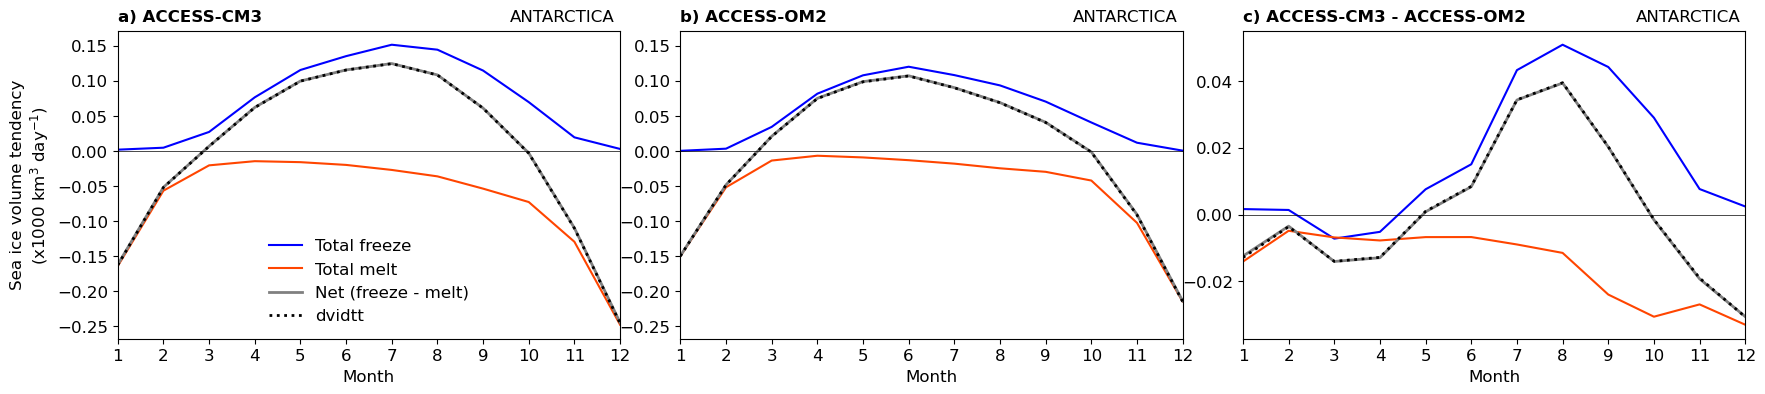

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


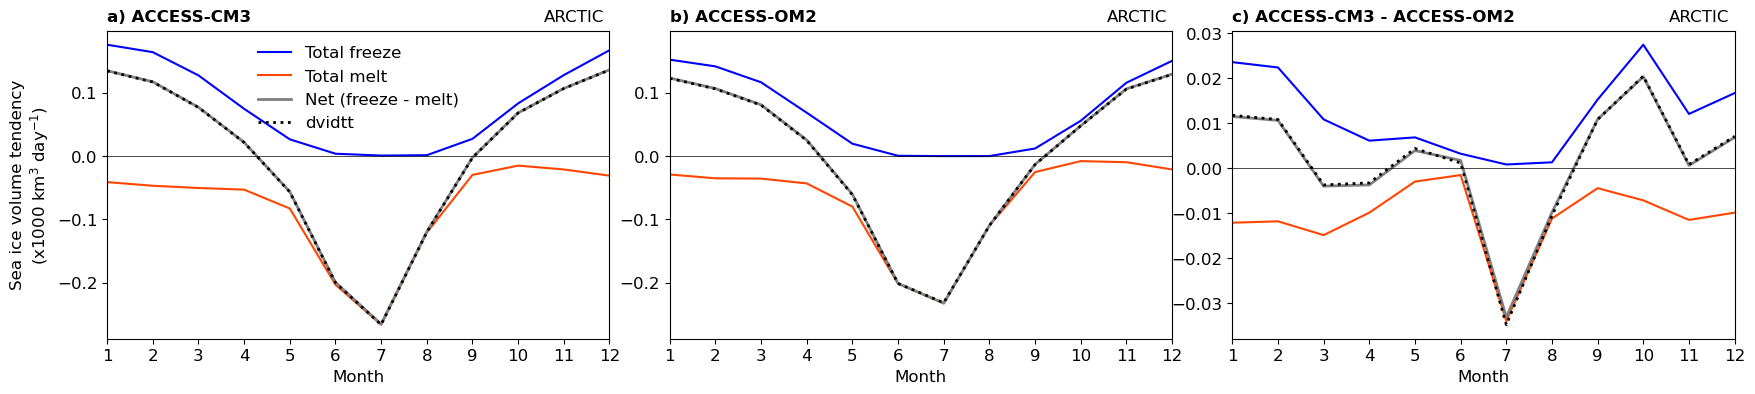

In [15]:
region_names = {'ANTARCTICA': 'Antarctic', 'ARCTIC': 'Arctic'}

def format_month_axis(ax):
    """Zero line and month ticks for a climatology panel"""
    ax.axhline(0, lw=0.5, c='k')
    ax.set_xlim([1,12])
    ax.set_xticks(np.arange(1,13,1))
    ax.set_xlabel('Month')

def plot_budget_totals(ax, clim):
    """Total freeze, total melt (as negative), net and dvidtt climatology, in 1000 km^3/day"""
    ax.plot(clim.month, clim['freeze']/1e12, c='blue', label='Total freeze')
    ax.plot(clim.month, -clim['melt']/1e12, c='orangered', label='Total melt')
    ax.plot(clim.month, (clim['freeze'] - clim['melt'])/1e12, c='grey', lw=2, label='Net (freeze - melt)')
    ax.plot(clim.month, clim['dvidtt_m']/1e12, c='k', ls=':', lw=2, label='dvidtt')

for region in ['ANTARCTICA', 'ARCTIC']:
    plt.rcParams['font.size'] = 12
    fig, axes = plt.subplots(ncols=3, figsize=(21,4), sharex=True)
    axes[1].sharey(axes[0])
    plt.subplots_adjust(wspace=0.12)

    panels = [
        (f'a) {model_label}', clim_om3[region]),
        (f'b) {ref_label}', clim_om2[region]),
        (f'c) {model_label} - {ref_label}', clim_om3[region] - clim_om2[region]),
    ]
    for ax, (title, clim) in zip(axes, panels):
        plot_budget_totals(ax, clim)
        format_month_axis(ax)
        ax.text(0.0, 1.03, title, fontsize=12, fontweight='bold', transform=ax.transAxes)
        ax.text(0.99, 1.03, region, ha='right', fontsize=12, transform=ax.transAxes)

    axes[0].set_ylabel('Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)')
    axes[0].legend(frameon=False, fontsize=12)

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"{region_names[region]} sea ice volume budget climatology comparing {model_label} and {ref_label}. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

### Check `freeze` - `melt` and `dvidtt` residuals

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


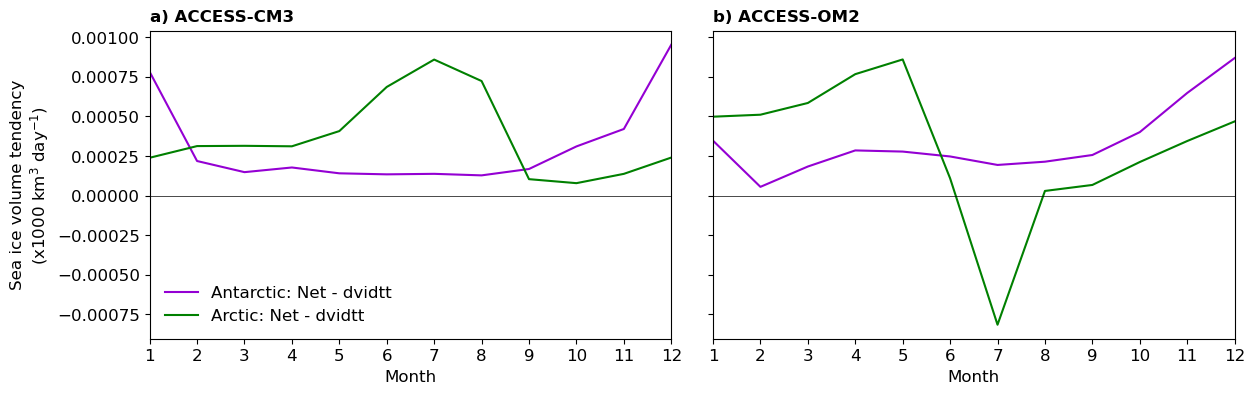

In [16]:
plt.rcParams['font.size'] = 12
fig, axes = plt.subplots(ncols=2, figsize=(14,4), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.08)

for ax, title, clim in zip(axes, [f'a) {model_label}', f'b) {ref_label}'], [clim_om3, clim_om2]):
    for region, c in [('ANTARCTICA', 'darkviolet'), ('ARCTIC', 'green')]:
        b = clim[region]
        ax.plot(b.month, ((b['freeze'] - b['melt']) - b['dvidtt_m'])/1e12, c=c, label=f'{region_names[region]}: Net - dvidtt')
    format_month_axis(ax)
    ax.text(0.0, 1.03, title, fontsize=12, fontweight='bold', transform=ax.transAxes)

axes[0].set_ylabel('Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)')
axes[0].legend(frameon=False, ncols=1, fontsize=12, loc='lower left')

mkmd.savefig(fig, "Sea Ice Mass Budget", f"Sea ice volume budget residual comparing {model_label} and {ref_label}. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
plt.show()

### Annual sea ice volume budget timeseries

Annual totals of each sea ice growth and melt component over the whole of each run, comparing ACCESS-OM3 and ACCESS-OM2 on each panel, with the climatology period (`t_slice`) shaded.

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


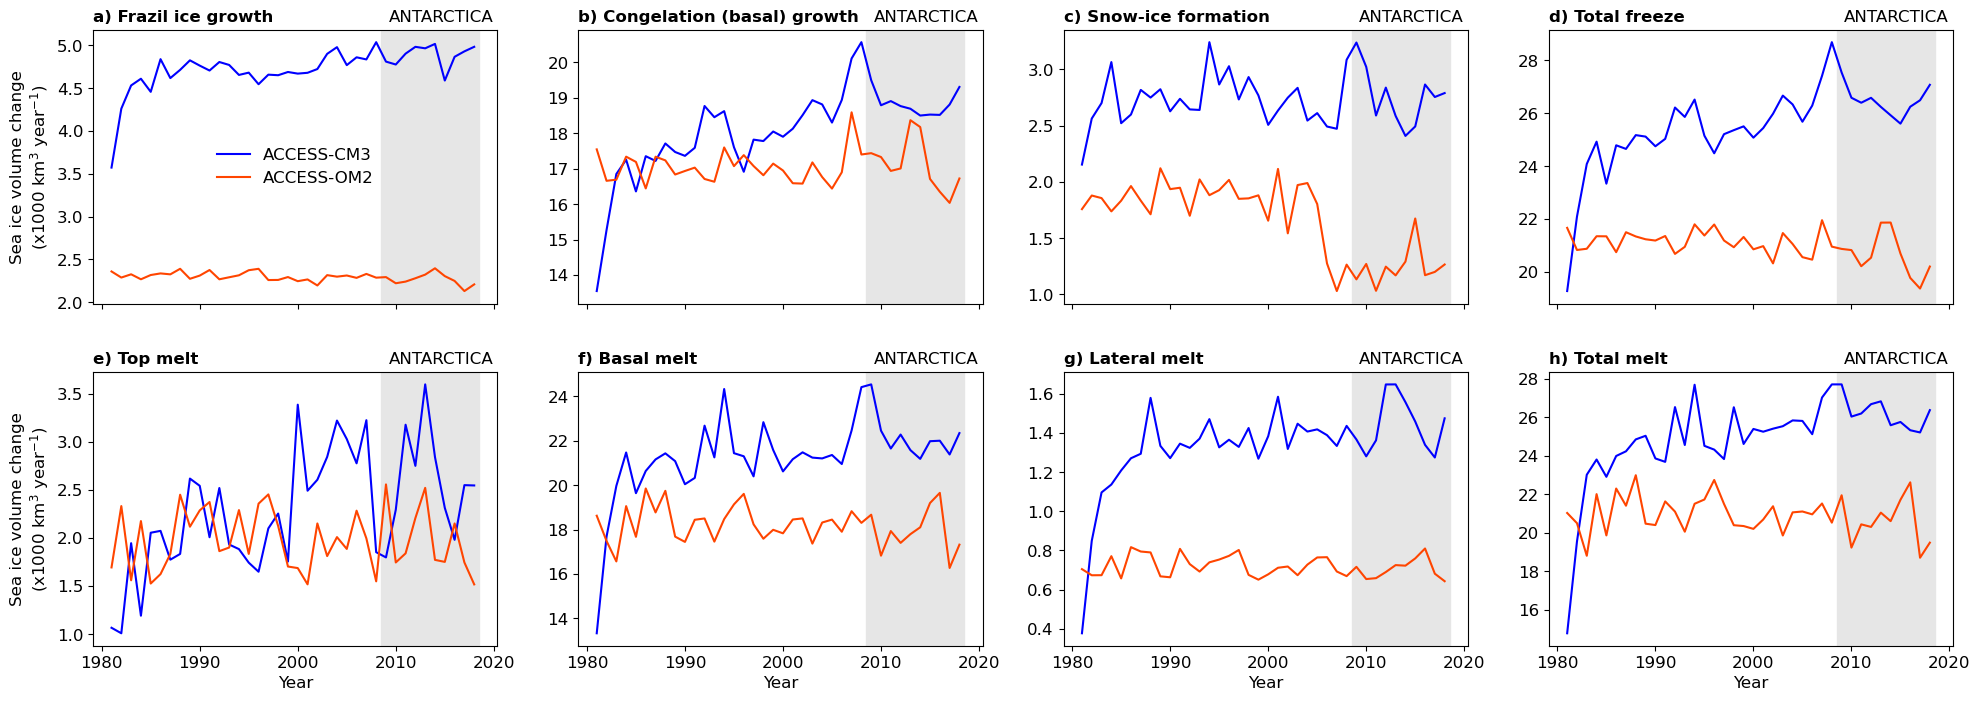

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


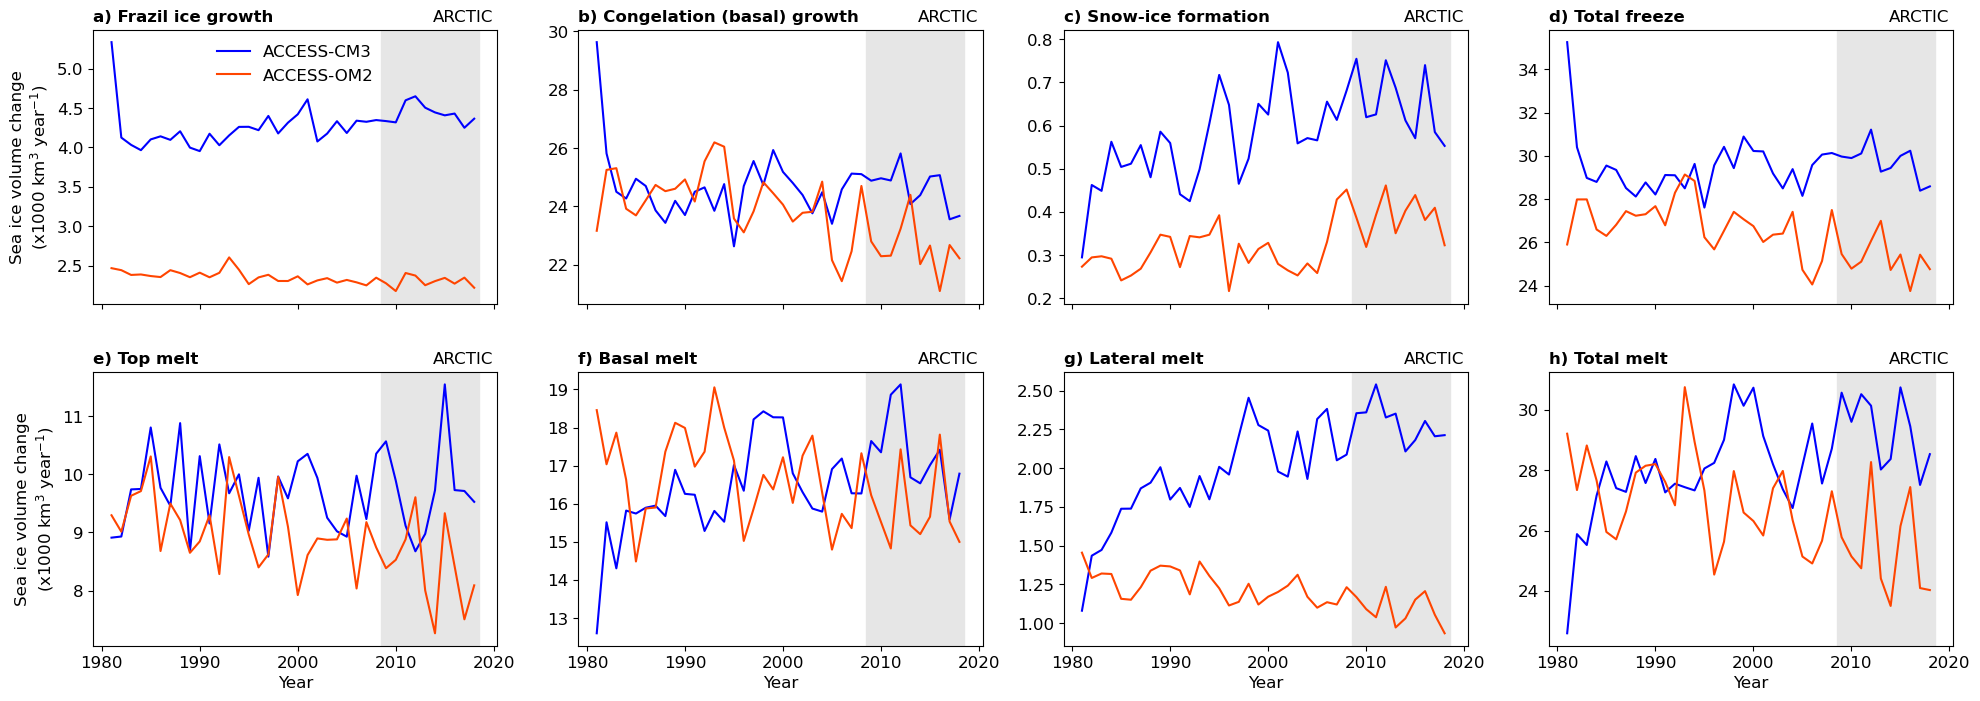

In [17]:
# Freeze components (top row) and melt components (bottom row), each with the total in the last column
budget_terms = [
    [('frazil_m', 'Frazil ice growth'), ('congel_m', 'Congelation (basal) growth'), ('snoice_m', 'Snow-ice formation'), ('freeze', 'Total freeze')],
    [('meltt_m', 'Top melt'), ('meltb_m', 'Basal melt'), ('meltl_m', 'Lateral melt'), ('melt', 'Total melt')],
]

def plot_budget_components(om3, om2, region, xdim, xlabel, ylabel):
    """
    2x4 panels of the sea ice growth and melt components and their totals, with the main
    experiment and the reference run on each panel. om3 and om2 are Datasets of the budget terms along xdim.
    """
    plt.rcParams['font.size'] = 12
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(24,8), sharex=True)
    plt.subplots_adjust(wspace=0.2, hspace=0.25)

    for row, terms in enumerate(budget_terms):
        for col, (term, name) in enumerate(terms):
            ax = axes[row, col]
            for model, data, c in [(model_label, om3, 'blue'), (ref_label, om2, 'orangered')]:
                ax.plot(data[xdim], data[term], c=c, label=model)
            ax.text(0.0, 1.03, f'{"abcdefgh"[4*row + col]}) {name}', fontsize=12, fontweight='bold', transform=ax.transAxes)
            ax.text(0.99, 1.03, region, ha='right', fontsize=12, transform=ax.transAxes)
        axes[row, 0].set_ylabel(ylabel)

    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    axes[0, 0].legend(frameon=False, fontsize=12)

    return fig, axes

for region in ['ANTARCTICA', 'ARCTIC']:
    fig, axes = plot_budget_components(
        annual_om3[region]/1e3, annual_om2[region]/1e3, region,  # km^3 -> 1000 km^3
        'year', 'Year', 'Sea ice volume change\n(x1000 km$^3$ year$^{-1}$)',
    )
    for ax in axes.flat:
        ax.axvspan(int(t_slice.start) - 0.5, int(t_slice.stop) + 0.5, color='0.9', zorder=0)  # climatology period

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"Annual {region_names[region]} sea ice growth and melt by component, comparing {model_label} and {ref_label}, with the climatology period shaded. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

### Sea ice volume budget climatology by component

Monthly climatology (over `t_slice`) of each sea ice growth and melt component, comparing ACCESS-OM3 and ACCESS-OM2 on each panel.

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_06.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


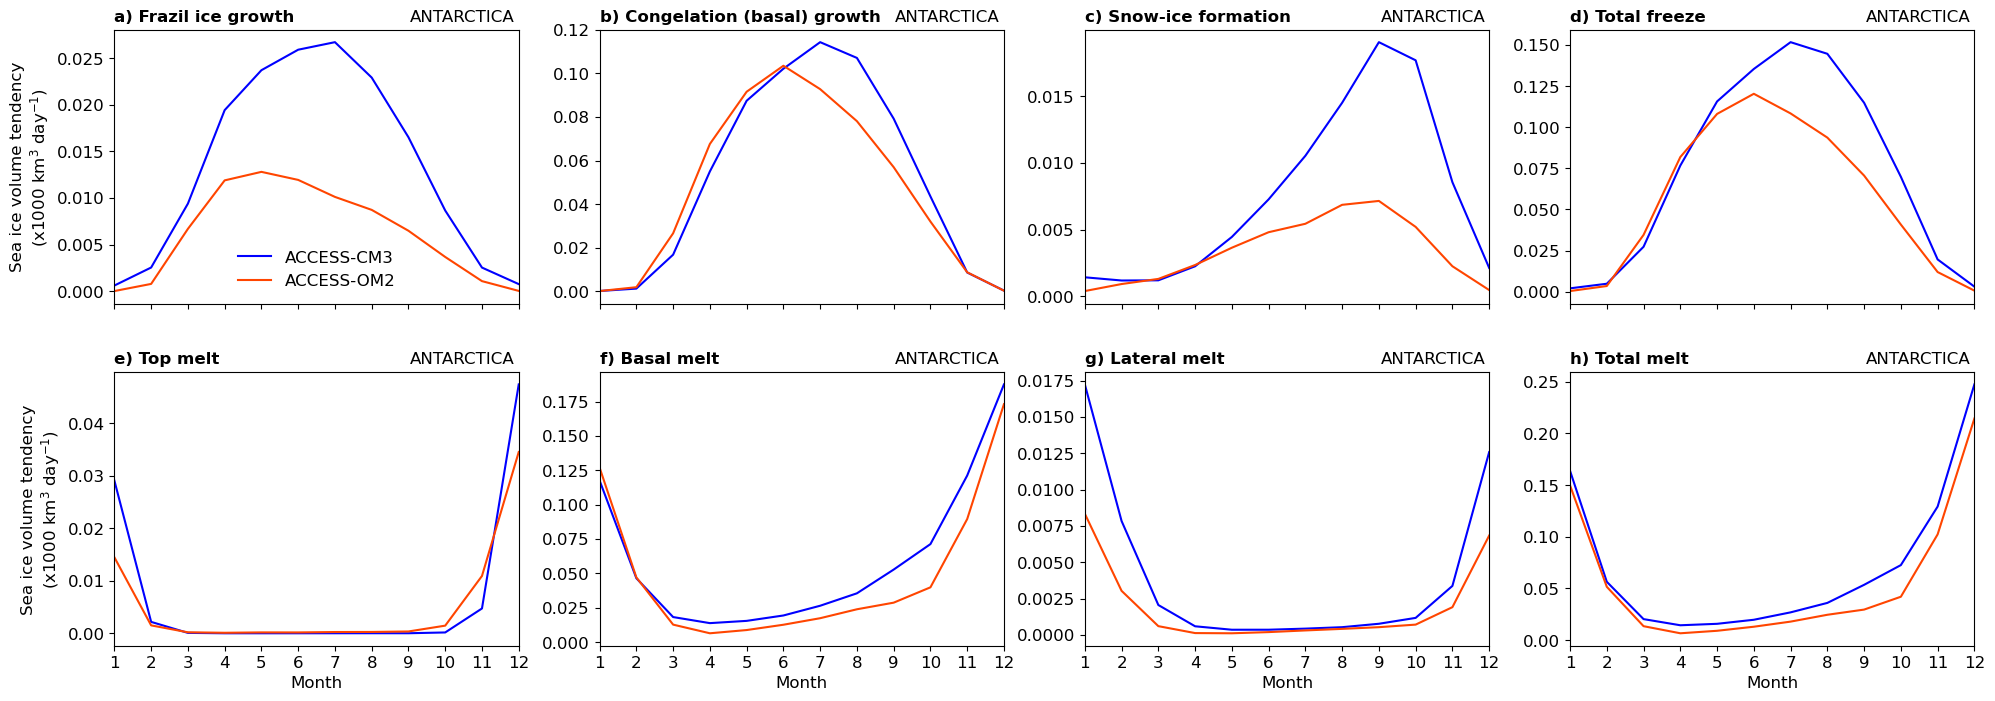

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_07.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


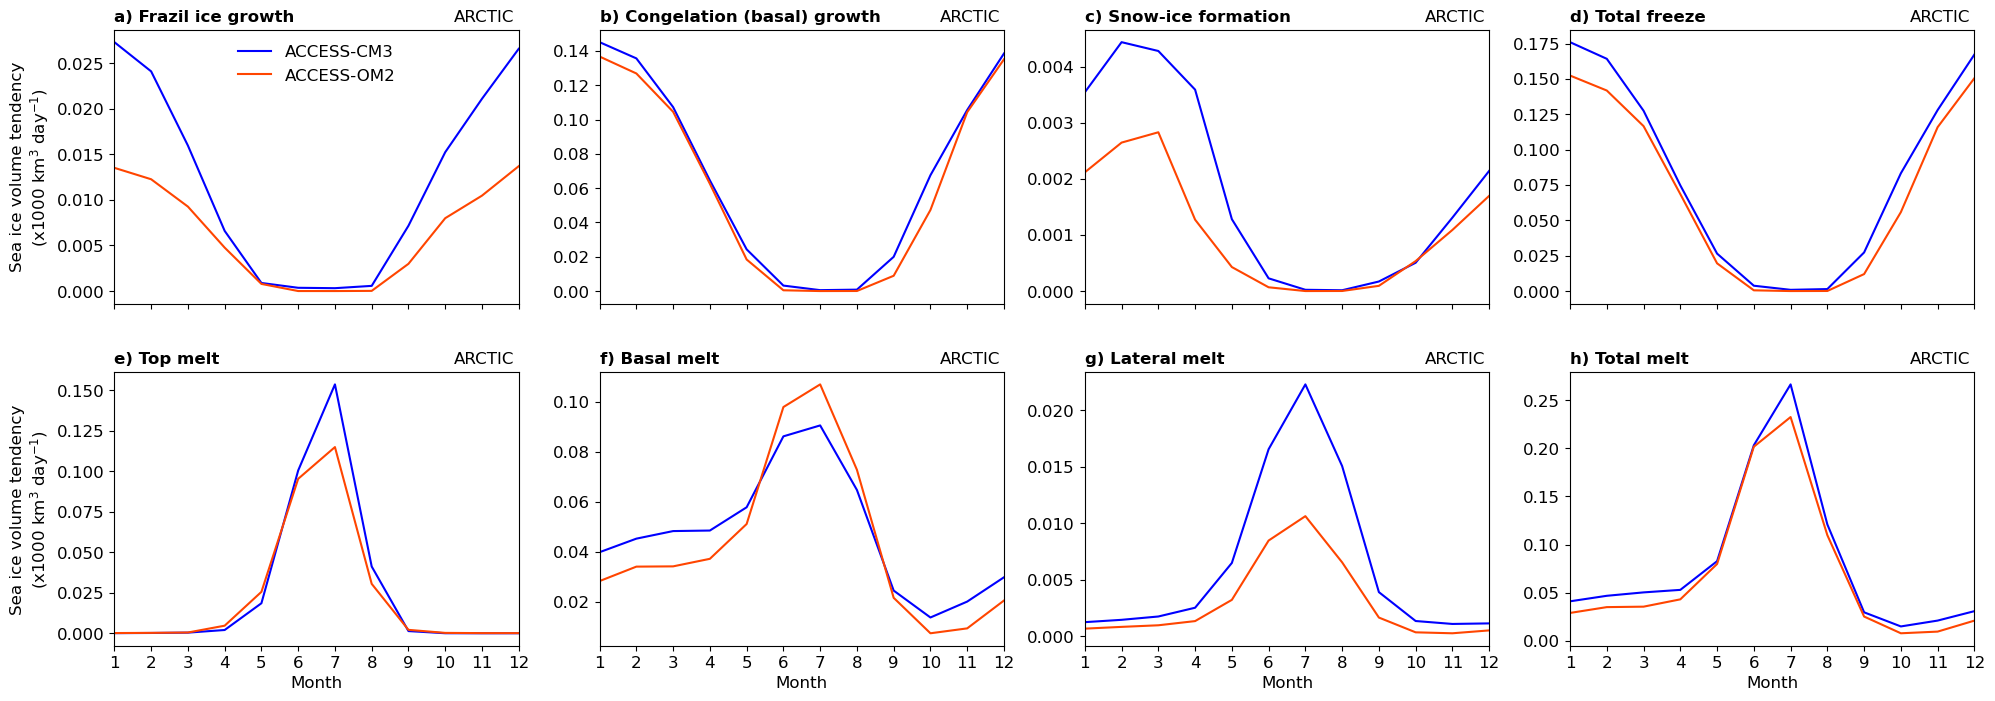

In [18]:
for region in ['ANTARCTICA', 'ARCTIC']:
    fig, axes = plot_budget_components(
        clim_om3[region]/1e12, clim_om2[region]/1e12, region,  # m^3 -> 1000 km^3
        'month', 'Month', 'Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)',
    )
    for ax in axes.flat:
        ax.set_xlim([1,12])
        ax.set_xticks(np.arange(1,13,1))

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"{region_names[region]} sea ice growth and melt climatology by component, comparing {model_label} and {ref_label}. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

### Maps of thermodynamic and dynamic ice volume tendency

Monthly climatologies (over `t_slice`) of the thermodynamic (`dvidtt`) and dynamic (`dvidtd`) ice volume tendencies in ACCESS-OM3, regridded onto the NSIDC 25 km polar-stereographic grid for each hemisphere (as in `SeaIce_area.ipynb`), with the model's 15% and 80% concentration contours.

In [19]:
map_months = {month: calendar.month_name[month] for month in range(1, 13)}
tendency_names = {"dvidtt_m": "thermodynamic", "dvidtd_m": "dynamic"}

dvidtd = datastore.search(variable="dvidtd_m", frequency="1mon").to_dask(
    xarray_open_kwargs = dict(chunks=full_field, decode_timedelta=True),
)
tendencies = ds[["dvidtt_m", "aice_m"]].assign(dvidtd_m=dvidtd.dvidtd_m).sel(time=t_slice)
tendency_clim = tendencies.groupby("time.month").mean("time").compute()

In [20]:
def fill_nan_nearest(arr):
    """Fill NaNs with the value of the nearest non-NaN grid cell."""
    nan_mask = np.isnan(arr)
    nearest = distance_transform_edt(nan_mask, return_distances=False, return_indices=True)
    return arr[tuple(nearest)]

# Native model grid (tripole) coordinates and land mask, from the CICE grid file.
# TLON/TLAT are NaN wherever tmask is NaN (masked-out cells); those points are
# excluded from regridding via the mask, but xesmf still needs a valid position
# for every grid point, so fill with the nearest defined neighbour (see SeaIce_area.ipynb).
tlat = grid.TLAT.values
native_mask = np.nan_to_num(grid.tmask.values, nan=0.0).astype(int)
# ESMF's bilinear stencil search is unreliable within ~0.5 deg of the true pole
# (see SeaIce_area.ipynb), so drop the few cells there.
native_mask[tlat > 89.5] = 0

native_grid = xr.Dataset(coords={
    "lon": (("nj", "ni"), fill_nan_nearest(grid.TLON.values)),
    "lat": (("nj", "ni"), fill_nan_nearest(tlat)),
})
native_grid["mask"] = (("nj", "ni"), native_mask)

# NSIDC polar-stereographic grids
nsidc_ancillary = {
    "Arctic": xr.open_dataset("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-nh/G02202-ancillary-psn25-v05r00.nc"),
    "Antarctic": xr.open_dataset("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-sh/G02202-ancillary-pss25-v05r00.nc"),
}

tendency_maps, model_ocean = {}, {}
for region, ancillary in nsidc_ancillary.items():
    regridder = xesmf.Regridder(native_grid, xr.Dataset(coords={"lon": ancillary.longitude, "lat": ancillary.latitude}),
                                method="bilinear", periodic=True, ignore_degenerate=True)
    tendency_maps[region] = regridder(tendency_clim).assign_coords(x=ancillary.x, y=ancillary.y).compute()
    # destination cells fed only by (masked) land come out as 0, so blank out land using the
    # regridded ocean fraction (see SeaIce_area.ipynb)
    ocean = regridder(xr.ones_like(native_grid.mask, dtype=float)).assign_coords(x=ancillary.x, y=ancillary.y)
    model_ocean[region] = (ocean > 0.5).compute()

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_08.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


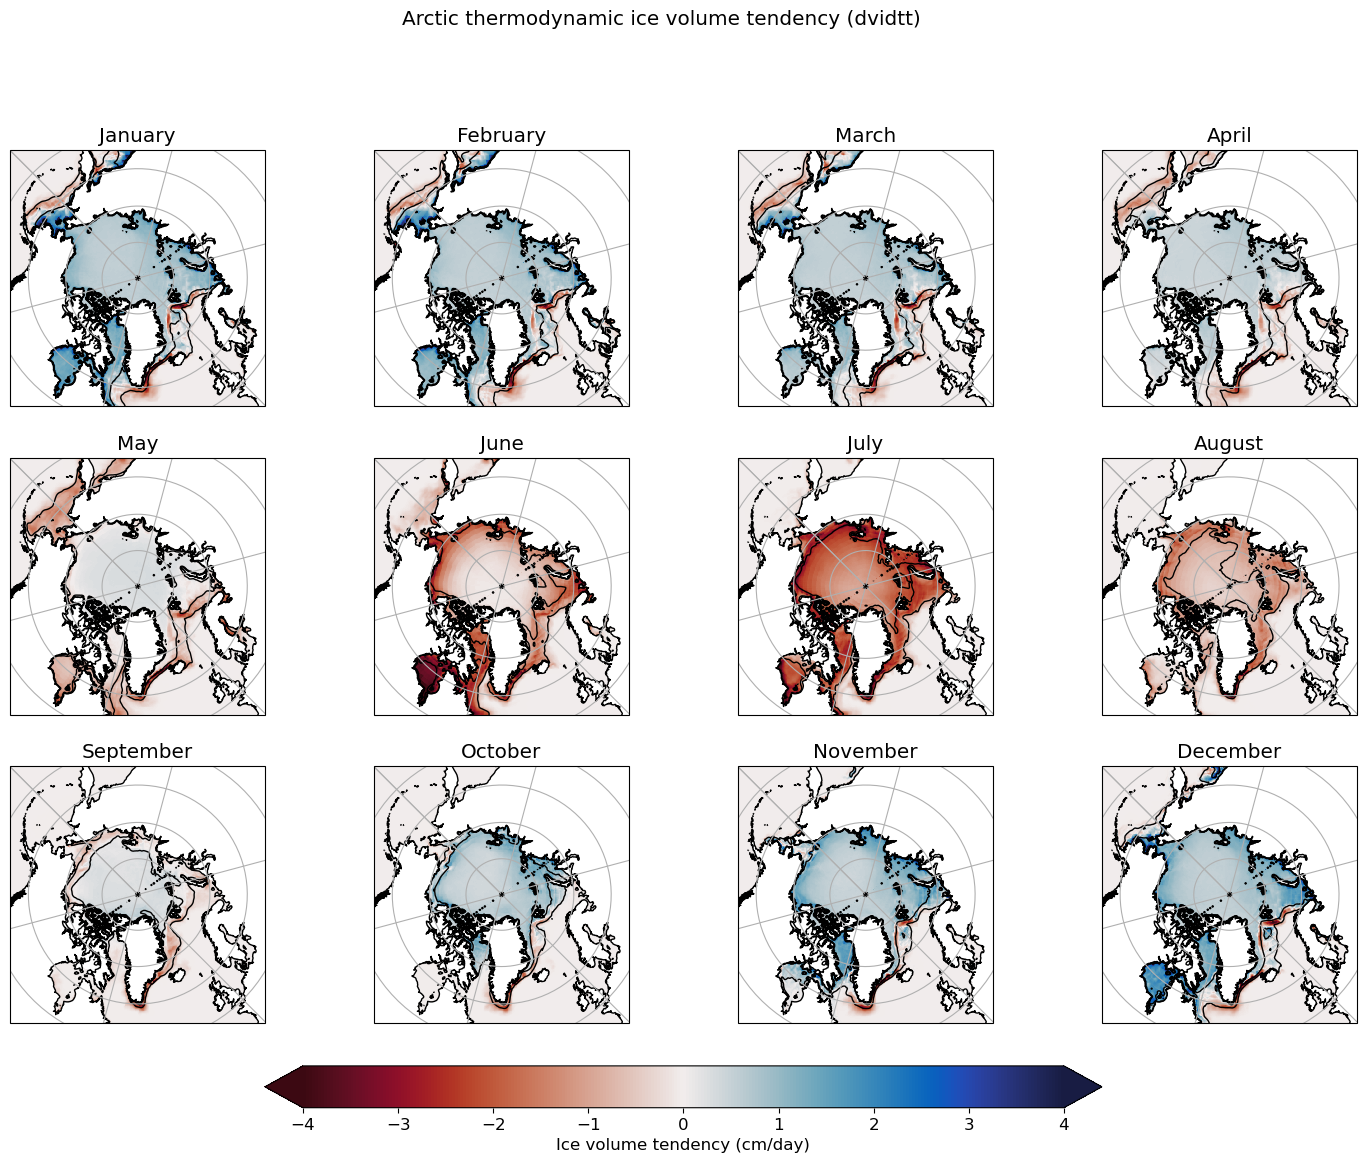

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_09.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


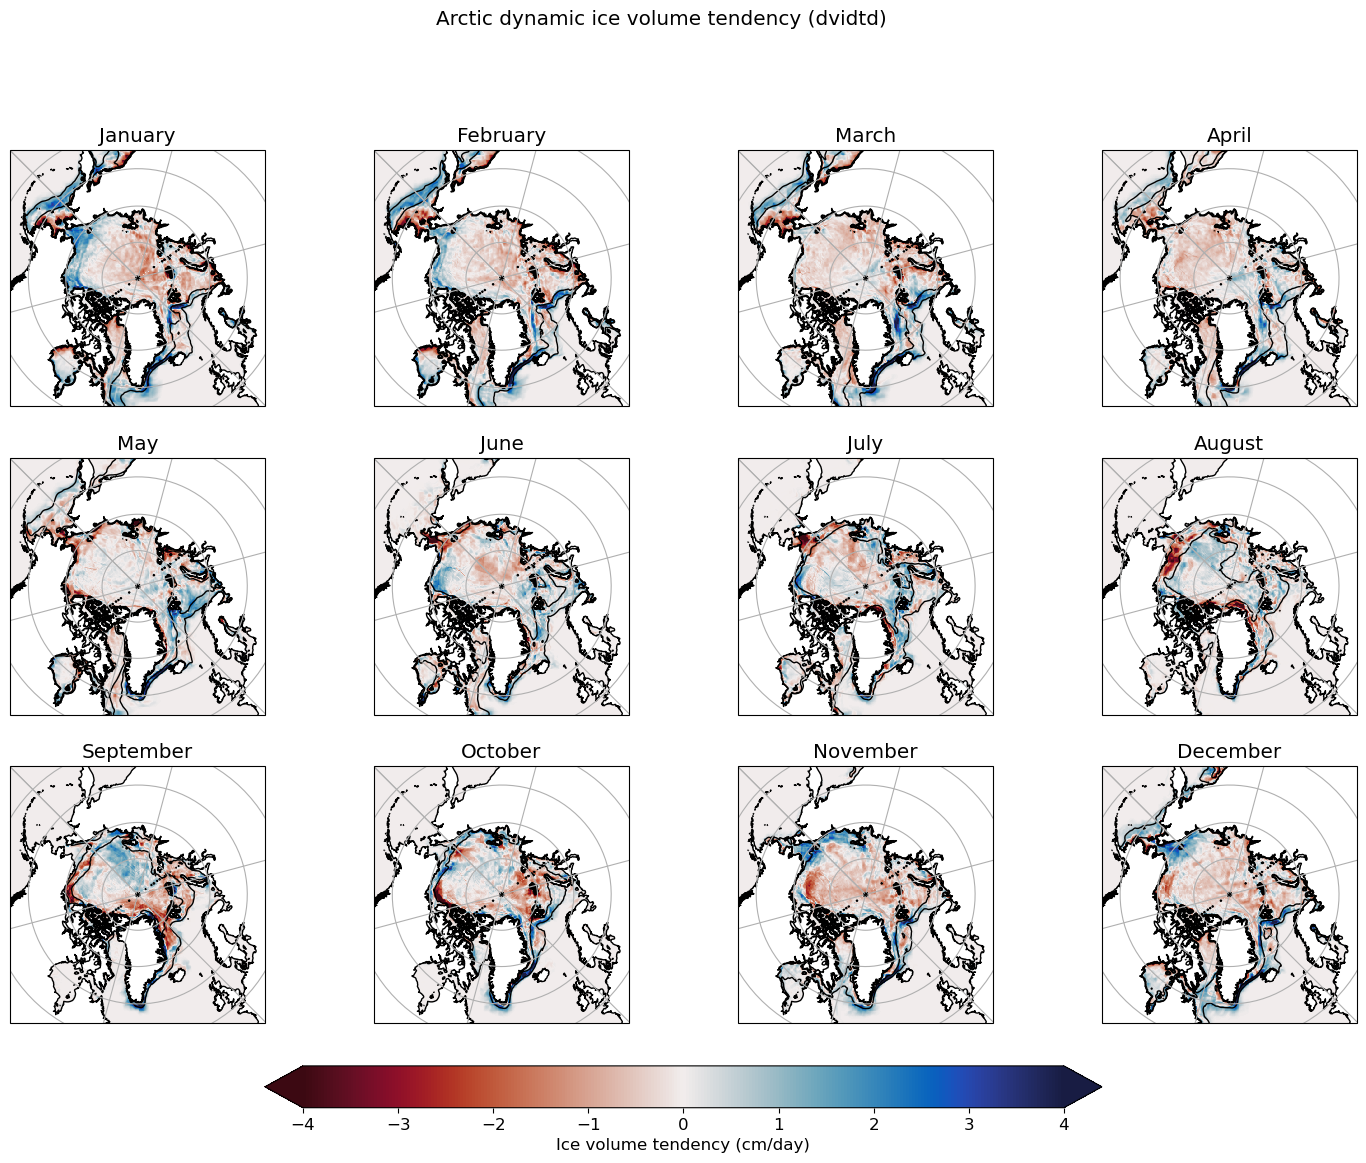

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_10.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


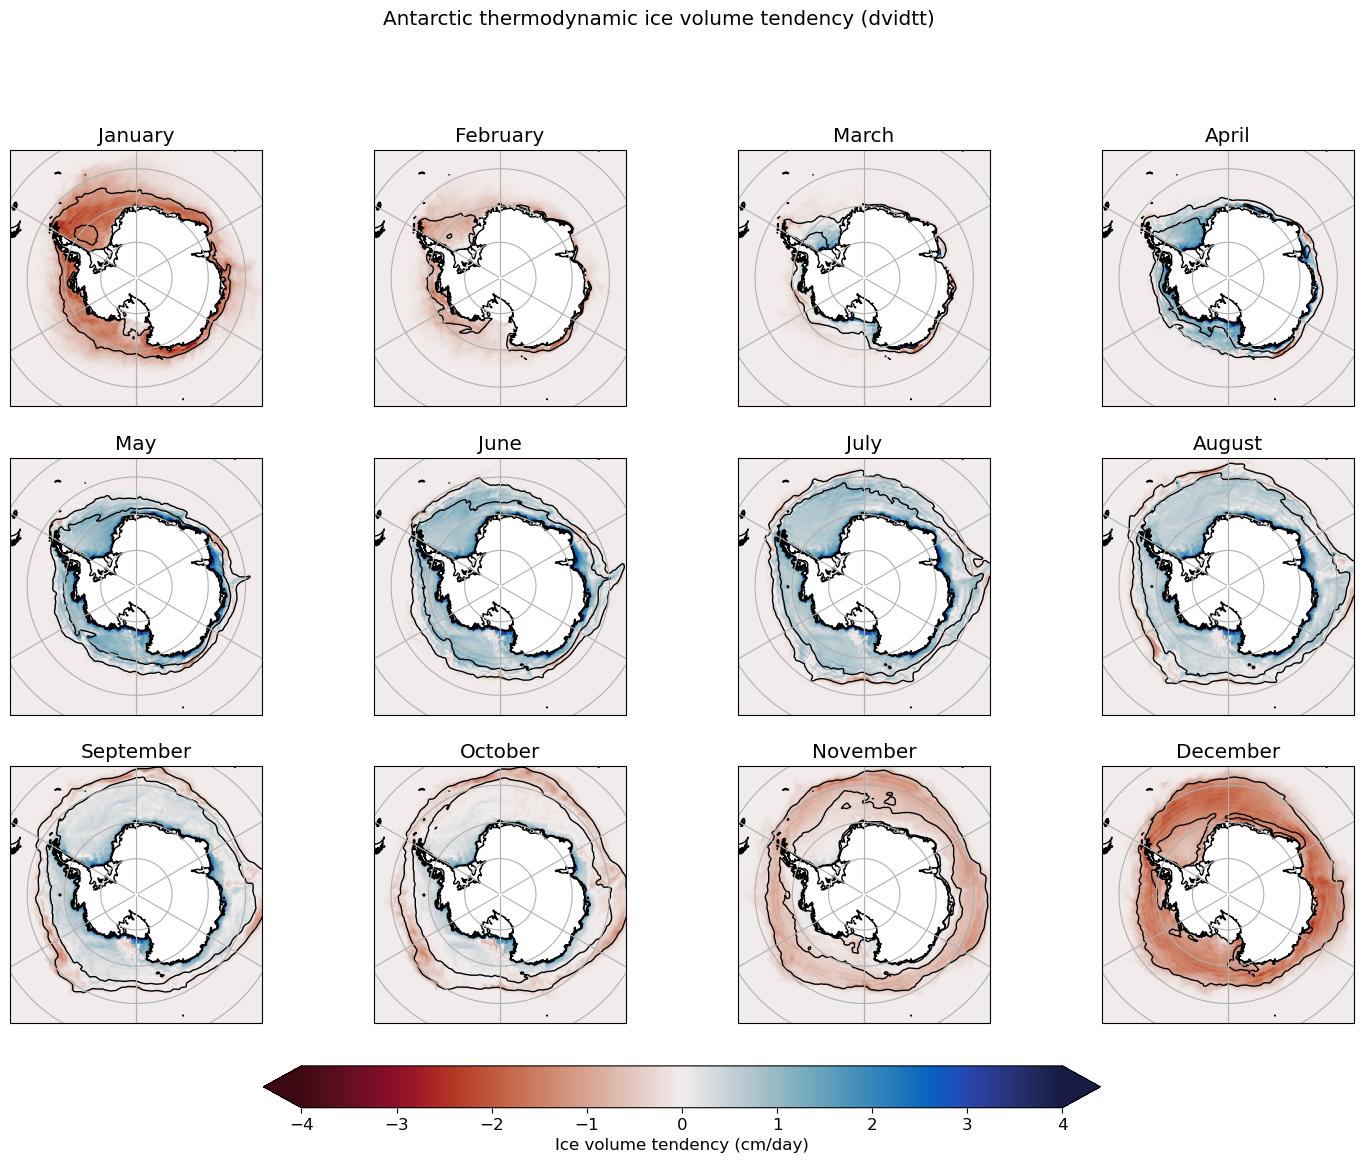

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology_11.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/SeaIce_mass_budget_climatology.md successfully.


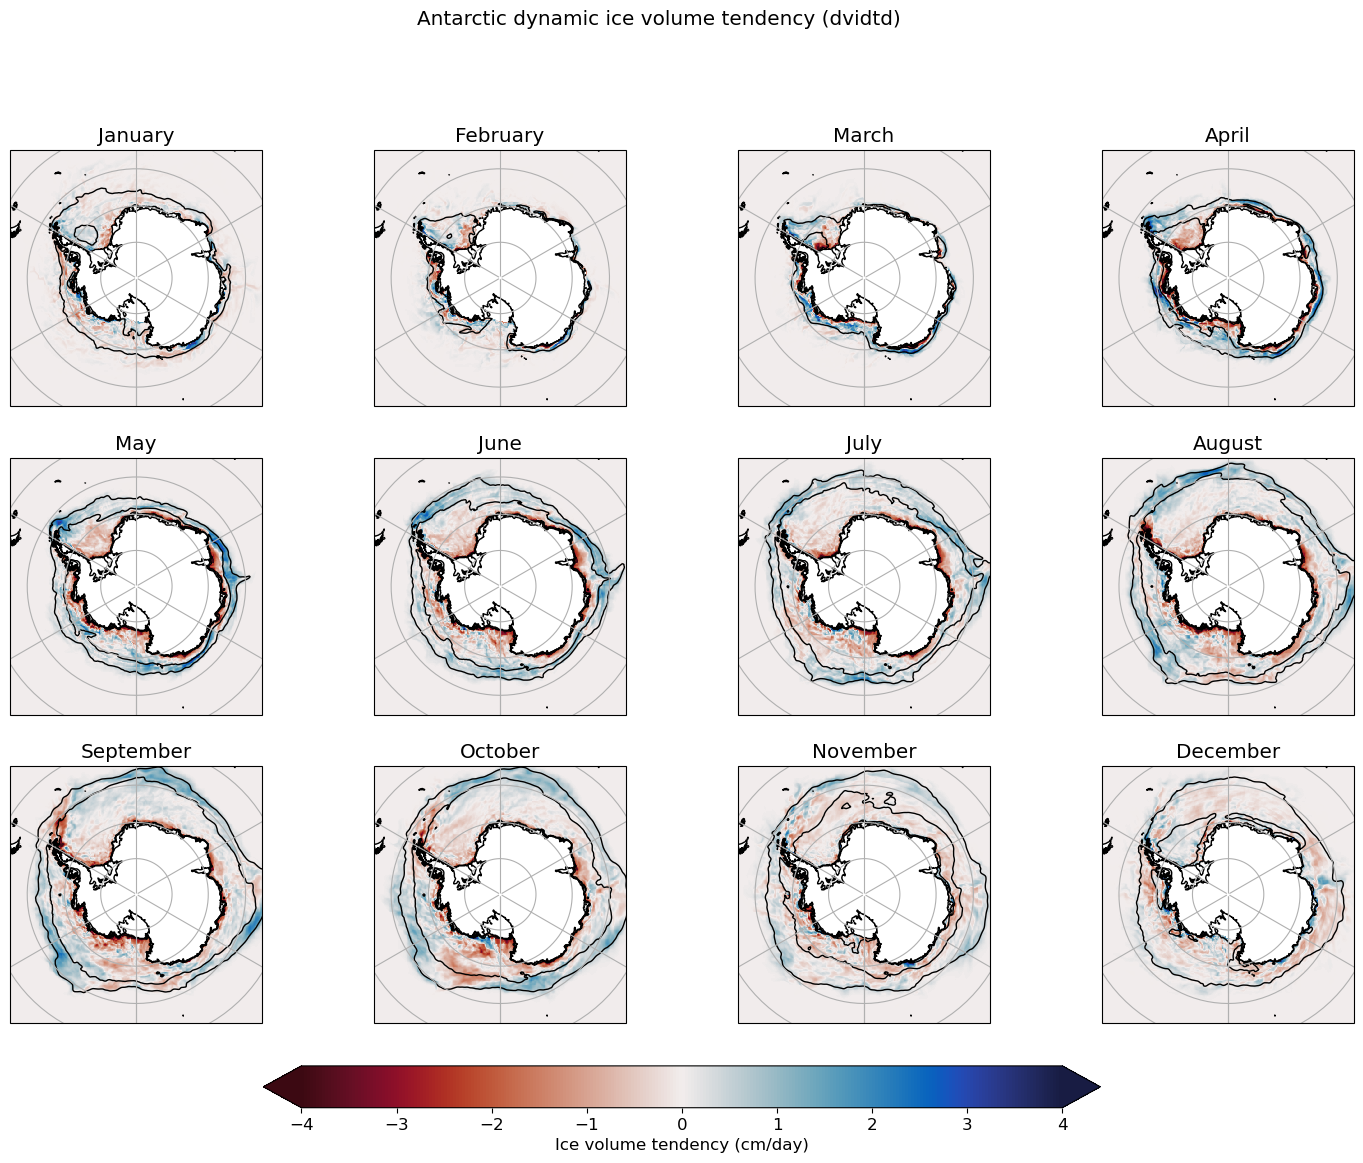

In [21]:
# Exact NSIDC polar-stereographic projections (EPSG:3411 North / EPSG:3412 South), as in SeaIce_area.ipynb
polar_globe = ccrs.Globe(semimajor_axis=6378273, semiminor_axis=6356889.449)
nsidc_crs = {
    "Arctic": ccrs.Stereographic(central_latitude=90, central_longitude=-45, true_scale_latitude=70, globe=polar_globe),
    "Antarctic": ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-70, globe=polar_globe),
}
nsidc_extent = {"Arctic": [-180, 180, 55, 90], "Antarctic": [-180, 180, -90, -55]}

for region, crs in nsidc_crs.items():
    for var, name in tendency_names.items():
        fig = plt.figure(figsize=(18, 14))
        axes = []
        for i, (month, month_name) in enumerate(map_months.items()):
            clim = tendency_maps[region].sel(month=month)
            ax = fig.add_subplot(3, 4, i + 1, projection=crs)
            data = clim[var].where(model_ocean[region])
            # blue where ice volume grows, red where it declines
            im = ax.pcolormesh(data.x, data.y, data, transform=crs, cmap=cmo.balance_r, vmin=-4, vmax=4)
            # model 15% and 80% concentration contours
            ax.contour(clim.x, clim.y, clim.aice_m, levels=[0.15, 0.8], colors="k", linewidths=1, transform=crs)
            ax.set_extent(nsidc_extent[region], ccrs.PlateCarree())
            ax.coastlines()
            ax.gridlines()
            ax.set_title(month_name)
            axes.append(ax)

        fig.suptitle(f"{region} {name} ice volume tendency ({var.removesuffix('_m')})")
        fig.colorbar(im, ax=axes, orientation="horizontal", shrink=0.6, pad=0.04, extend="both",
                     label="Ice volume tendency (cm/day)")

        mkmd.savefig(fig, "Sea Ice Mass Budget", f"{region} monthly climatology ({t_slice.start}-{t_slice.stop}) of the {model_label} {name} ice volume tendency ({var.removesuffix('_m')}), with the model 15% and 80% concentration contours. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)", dpi=150)
        plt.show()

In [22]:
client.close()